# 10 — Robustness and interpretability

Phase 36 perturbation results and the Phase 35 interpretability status.

**Evidence base**

- `reports/audits/phase36_robustness_scientific_result_v1_23.json`
- `reports/audits/phase35_interpretability_scientific_result_v1_0.json`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 10.1 Execution integrity

In [3]:
r = json.loads((REPO / "reports/audits/phase36_robustness_scientific_result_v1_23.json").read_text(encoding="utf-8"))
for k in ("clean_passes", "perturbed_g_forwards", "test_reads", "training",
          "optimizer_steps", "parameter_mutations"):
    print(f"  {k:22s}: {r['counters'][k]}")
print()
ce = r["clean_equivalence"]
print("clean equivalence all_pass :", ce["all_pass"])
print("dice mismatches            :", len(ce["dice_mismatches"]))
print("max |Δ Dice| vs frozen     :", ce.get("max_abs_dice_difference", 0.0))

  clean_passes          : 808
  perturbed_g_forwards  : 12928
  test_reads            : 0
  training              : 0
  optimizer_steps       : 0
  parameter_mutations   : 0

clean equivalence all_pass : True
dice mismatches            : 0
max |Δ Dice| vs frozen     : 0.0


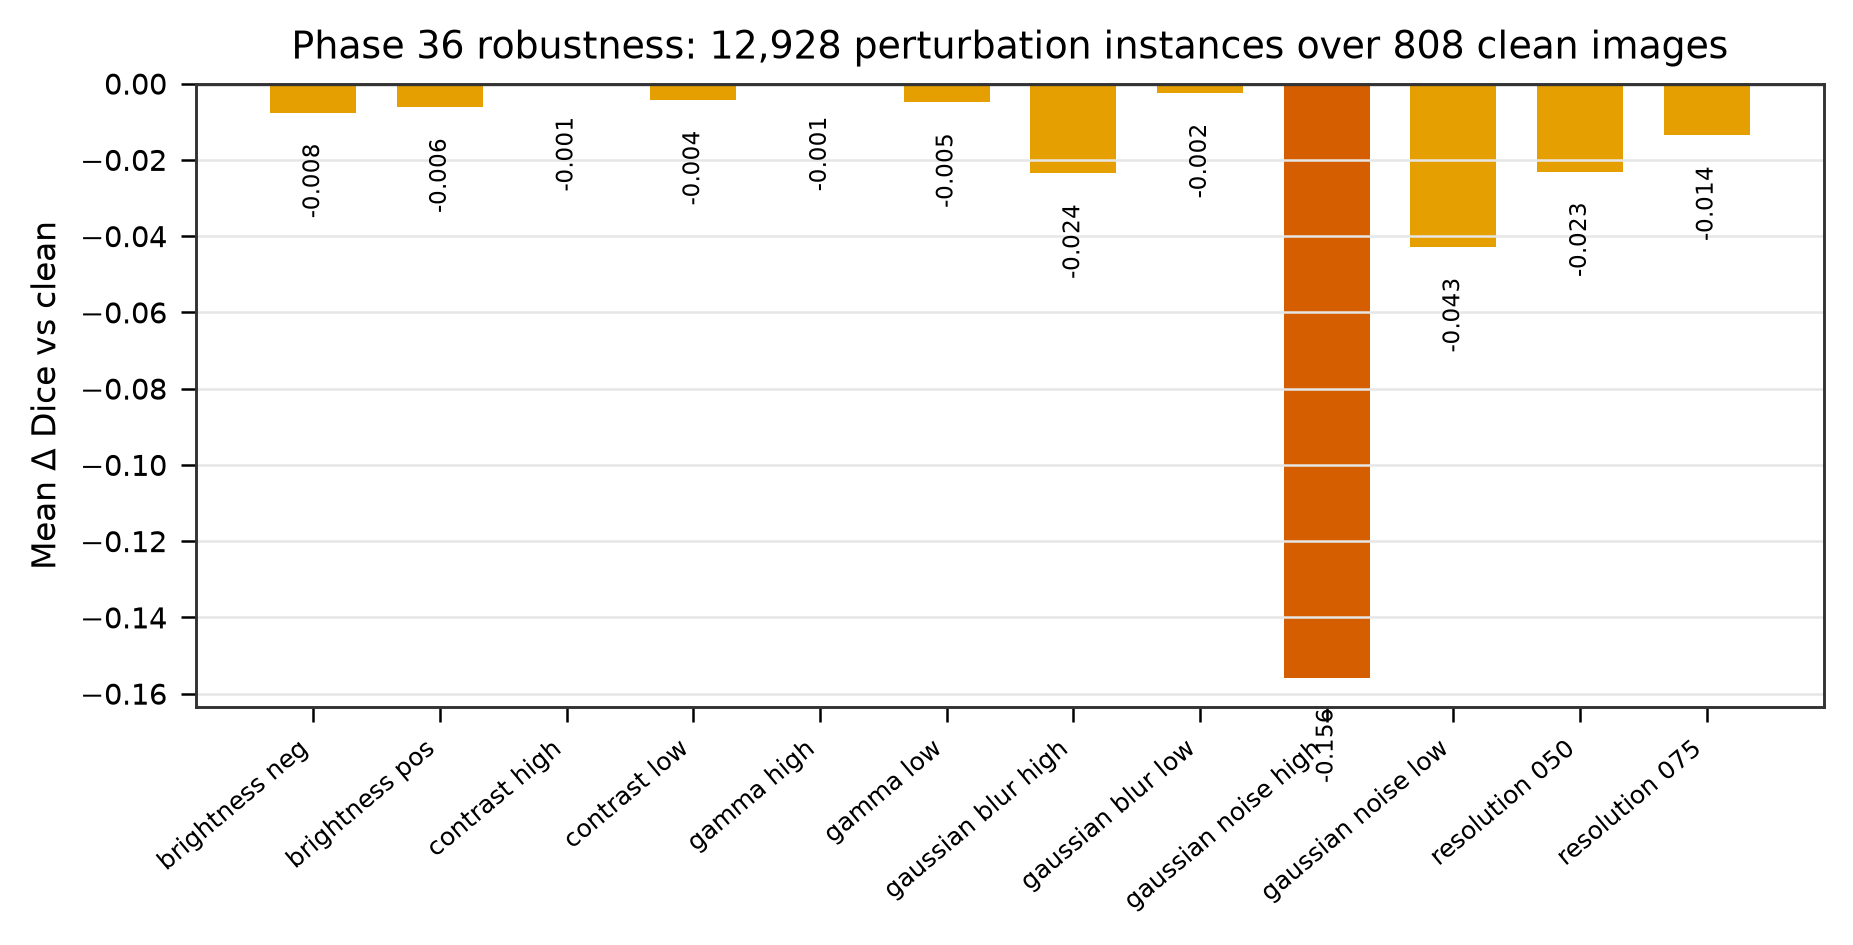

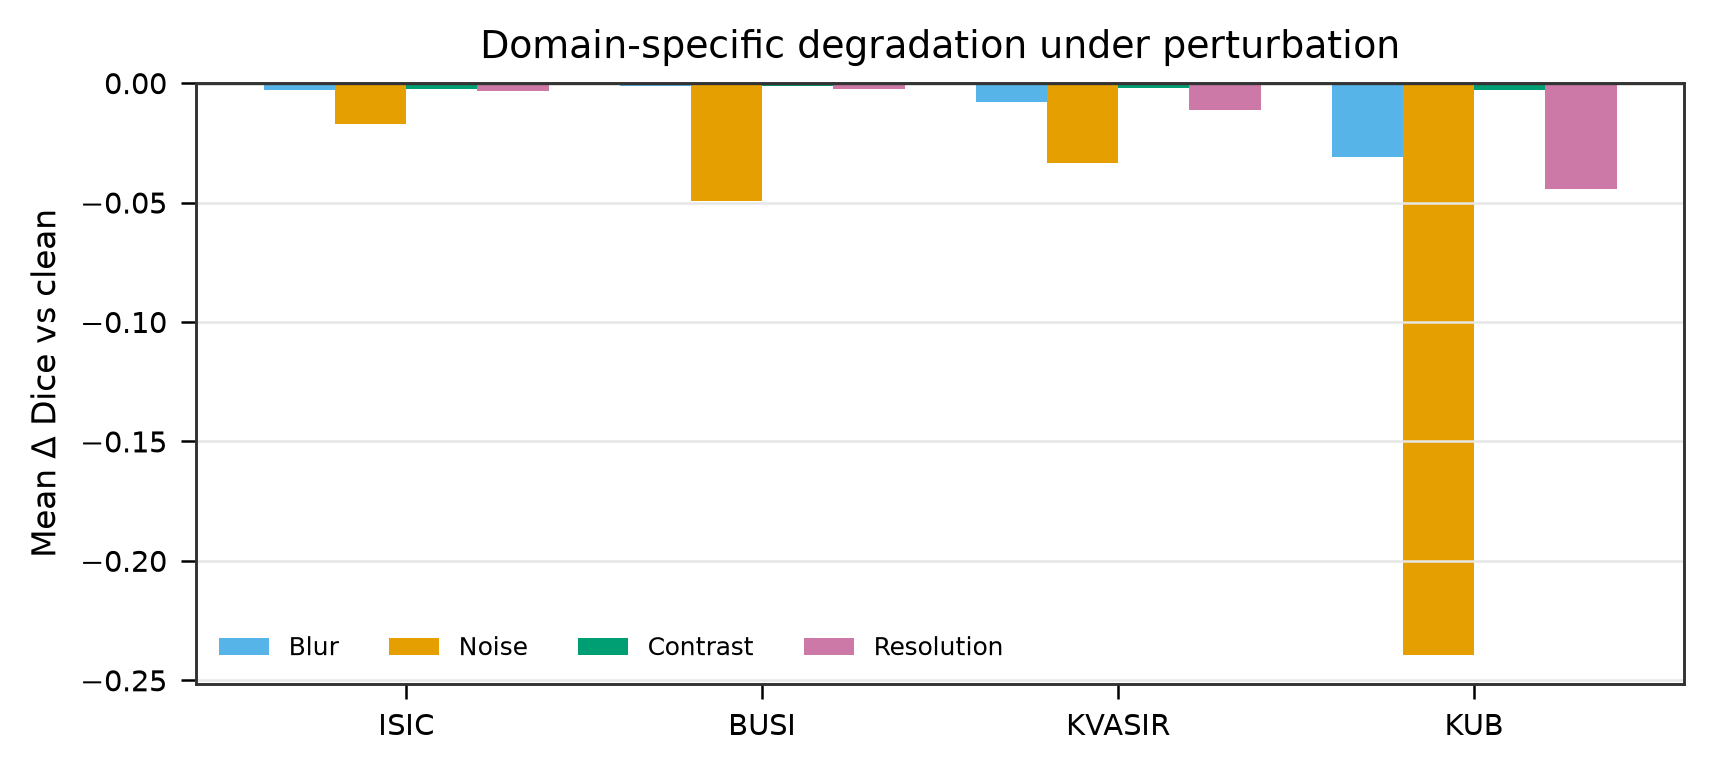

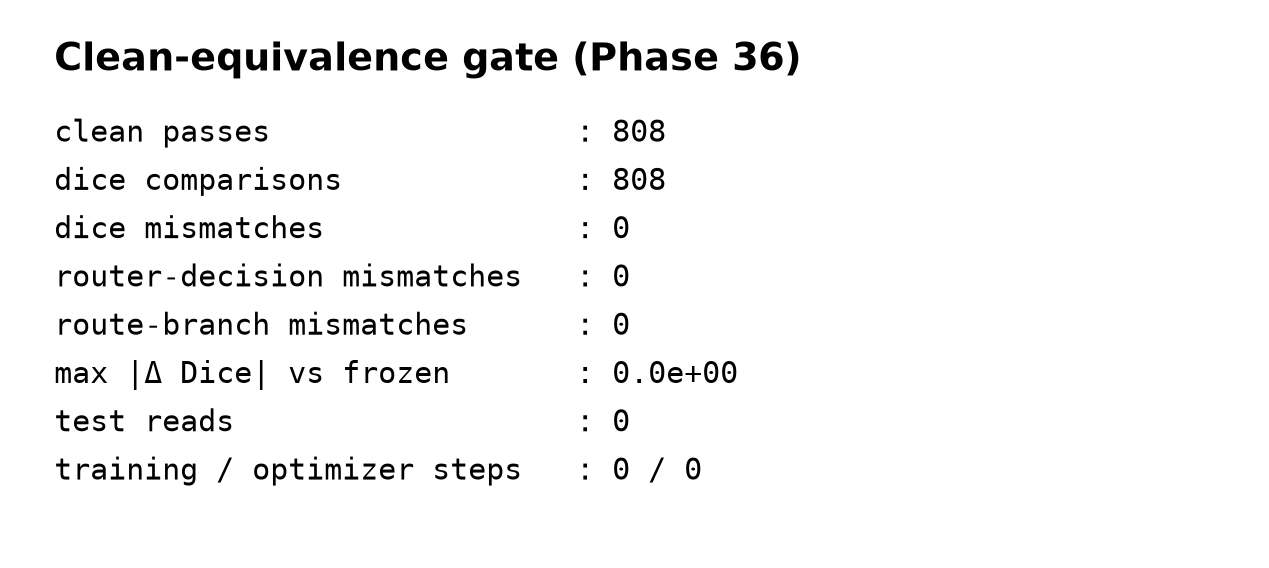

In [4]:
fig("Robustness", "ROB01_perturbation_degradation", width=800)
fig("Robustness", "ROB02_domain_degradation", width=720)
fig("Robustness", "ROB03_clean_equivalence_gate", width=580)

## 10.2 The KUB weakness

In [5]:
rows = pd.DataFrame(r["image_rows"])
kub = (rows[rows.domain == "KUB"].groupby("condition").paired_delta_dice.mean()
           .sort_values())
print("KUB mean Δ Dice by condition (worst first):")
print(kub.head(6).round(4).to_string())
print()
print("Worst single KUB image delta:",
      round(float(rows[rows.domain == "KUB"].paired_delta_dice.min()), 4))

KUB mean Δ Dice by condition (worst first):
condition
GAUSSIAN_NOISE_HIGH   -0.3636
GAUSSIAN_NOISE_LOW    -0.1153
GAUSSIAN_BLUR_HIGH    -0.0563
RESOLUTION_050        -0.0544
RESOLUTION_075        -0.0342
BRIGHTNESS_NEG        -0.0167

Worst single KUB image delta: -0.9211


## 10.3 Interpretability — honest status

In [6]:
p35 = json.loads((REPO / "reports/audits/phase35_interpretability_scientific_result_v1_0.json").read_text(encoding="utf-8"))
print("Phase 35 terminal:", p35.get("terminal_state", p35.get("status", "PRESENT")))
for k, v in list(p35.items())[:12]:
    if not isinstance(v, (dict, list)):
        print(f"  {k}: {v}")

Phase 35 terminal: PRESENT
  artifact: phase35_interpretability_scientific_result_v1_0
  section: §V
  phase: 35
  method: RA-MedFiLM-BARR
  revision: ra_medfilm_barr_phase35_interpretability_v1_0
  classification: PHASE35_FIRST_SCIENTIFIC_EXECUTION_RESULT
  claim_type: DESCRIPTIVE_MODEL_MECHANISM_EVIDENCE
  families_never_merged: True


In [7]:
print("INTERPRETABILITY DISCLOSURE")
print("---------------------------")
print("Phase 35 produced task-conditioning diagnostics and FiLM response records.")
print("It did NOT produce a causal attribution study: no counterfactual FiLM")
print("ablation was executed, and no saliency map is offered as evidence of")
print("causation. Claims here are descriptive.")

INTERPRETABILITY DISCLOSURE
---------------------------
Phase 35 produced task-conditioning diagnostics and FiLM response records.
It did NOT produce a causal attribution study: no counterfactual FiLM
ablation was executed, and no saliency map is offered as evidence of
causation. Claims here are descriptive.


In [8]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
